# Notebook 02 — Mathematical Foundations for Deep Learning

**Track:** Deep Learning with PyTorch | **Language:** English | **Level:** Beginner → Intermediate

This notebook builds the mathematical intuition behind neural networks before moving to deeper PyTorch implementations.

## Learning objectives
- Represent data with scalars, vectors, matrices, and tensors.
- Use vector operations, dot products, and matrix multiplication.
- Understand functions, derivatives, partial derivatives, and gradients.
- Explain the chain rule and its role in backpropagation.
- Understand loss functions and gradient descent.
- Verify derivatives with PyTorch autograd.
- Train and visualize a simple linear model.

**Workflow:** Read the explanation, run the commented code, inspect the output, and complete the exercises at the end.

## 1. The mathematical building blocks

Deep learning uses several areas of mathematics:

| Area | Role in deep learning |
|---|---|
| Linear algebra | Represents data, weights, and layer computations |
| Calculus | Measures how outputs change as inputs or parameters change |
| Probability and statistics | Describes variation, uncertainty, and data |
| Optimization | Updates parameters to reduce prediction error |

A neural network is a parameterized function. Training adjusts its parameters so that its predictions become more useful for a task.

## 2. Scalars, vectors, matrices, and tensors

- **Scalar:** a single number, such as a loss value.
- **Vector:** a one-dimensional collection of numbers, such as a feature vector.
- **Matrix:** a two-dimensional array, such as a batch of examples.
- **Tensor:** a general multidimensional numerical array. PyTorch tensors can represent all of the above.

The **shape** tells us the size along each axis. For example, `(4, 3)` means four rows and three columns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A scalar, vector, matrix, and 3D tensor.
scalar = 3.14
vector = np.array([1.0, 2.0, 3.0])
matrix = np.array([[1, 2, 3], [4, 5, 6]])
tensor_3d = np.zeros((4, 5, 3))

print("Scalar:", scalar)
print("Vector shape:", vector.shape)
print("Matrix shape:", matrix.shape)
print("3D tensor shape:", tensor_3d.shape)

# A batch contains four examples with three features per example.
X = np.array([[0.2, 0.5, 0.1],
              [0.9, 0.1, 0.4],
              [0.3, 0.8, 0.7],
              [0.6, 0.2, 0.9]])
print("Batch shape:", X.shape)

Scalar: 3.14
Vector shape: (3,)
Matrix shape: (2, 3)
3D tensor shape: (4, 5, 3)
Batch shape: (4, 3)


## 3. Vector operations and dot products

For vectors $\mathbf{a}$ and $\mathbf{b}$ with the same shape, addition is element-wise. The dot product multiplies corresponding elements and then sums them:

$$
\mathbf{a}\cdot\mathbf{b}=\sum_{i=1}^{n}a_i b_i
$$

A neuron often computes a weighted sum plus a bias:

$$
z=\mathbf{w}\cdot\mathbf{x}+b
$$

Here, $\mathbf{x}$ contains input features, $\mathbf{w}$ contains learnable weights, and $b$ is a learnable bias.

In [2]:
# Compare element-wise operations with the dot product.
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 5.0, 6.0])

print("a + b:", a + b)
print("a * b (element-wise):", a * b)
print("a dot b:", np.dot(a, b))

# Compute one neuron's weighted sum.
x = np.array([0.7, 0.2, 0.9])
w = np.array([0.4, -0.3, 0.8])
bias = 0.1
contributions = w * x
z = contributions.sum() + bias

print("Feature contributions:", contributions)
print("Pre-activation z:", z)

a + b: [5. 7. 9.]
a * b (element-wise): [ 4. 10. 18.]
a dot b: 32.0
Feature contributions: [ 0.28 -0.06  0.72]
Pre-activation z: 1.04


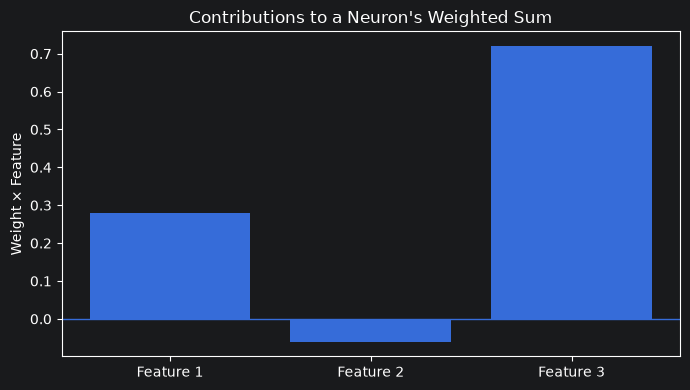

In [3]:
# Plot each feature's contribution to the neuron's weighted sum.
plt.figure(figsize=(7, 4))
plt.bar(["Feature 1", "Feature 2", "Feature 3"], contributions)
plt.axhline(0, linewidth=1)
plt.ylabel("Weight × Feature")
plt.title("Contributions to a Neuron's Weighted Sum")
plt.tight_layout()
plt.show()

## 4. Matrix multiplication and dense layers

Matrix multiplication allows many weighted sums to be calculated efficiently. If $X$ has shape $(m,n)$ and $W$ has shape $(n,k)$, then $XW$ has shape $(m,k)$:

$$
(m,n)\ @\ (n,k)\rightarrow(m,k)
$$

A dense layer commonly computes:

$$
Z=XW+b
$$

The bias contains one value per output unit and is broadcast across the batch. In NumPy, `A * B` is element-wise multiplication; `A @ B` is matrix multiplication.

In [4]:
# Four examples, three input features, and two output units.
X = np.array([[0.2, 0.5, 0.1],
              [0.9, 0.1, 0.4],
              [0.3, 0.8, 0.7],
              [0.6, 0.2, 0.9]])
W = np.array([[0.2, -0.1],
              [0.4,  0.3],
              [-0.5, 0.8]])
b = np.array([0.05, 0.10])

# Matrix multiplication computes both output units for all examples.
Z = X @ W + b
print("X shape:", X.shape)
print("W shape:", W.shape)
print("Output shape:", Z.shape)
print("Z:\n", Z)

X shape: (4, 3)
W shape: (3, 2)
Output shape: (4, 2)
Z:
 [[ 0.24  0.31]
 [ 0.07  0.36]
 [ 0.08  0.87]
 [-0.2   0.82]]


## 5. Linear and affine transformations

A layer computes a weighted sum. With a bias, it is technically an **affine transformation**:

$$
\mathbf{z}=W\mathbf{x}+\mathbf{b}
$$

A neural network usually applies a nonlinear activation after this transformation:

$$
\mathbf{a}=f(\mathbf{z})
$$

Without nonlinear activations between layers, stacking affine transformations is equivalent to one larger affine transformation. Nonlinearity lets networks represent more complex relationships.

## 6. Functions and derivatives

A function maps an input to an output. For example:

$$
f(x)=x^2,\qquad f'(x)=2x
$$

The derivative measures the instantaneous rate of change. At $x=1.5$, the derivative is $3$: near that point, a small input change produces approximately three times that change in the output.

In optimization, derivatives tell us how a small parameter change is expected to affect the loss.

f(x0): 2.25
f'(x0): 3.0


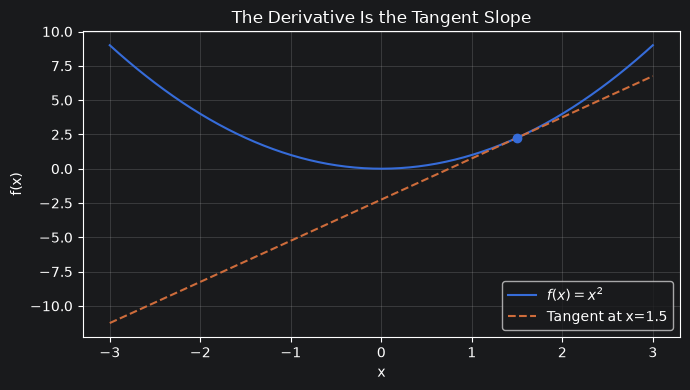

In [5]:
# Define a function and its analytical derivative.
def f(x):
    return x**2

def df(x):
    return 2*x

x0 = 1.5
print("f(x0):", f(x0))
print("f'(x0):", df(x0))

# Plot the function and its tangent line at x0.
x_values = np.linspace(-3, 3, 300)
y_values = f(x_values)
slope = df(x0)
tangent = f(x0) + slope * (x_values - x0)

plt.figure(figsize=(7, 4))
plt.plot(x_values, y_values, label="$f(x)=x^2$")
plt.plot(x_values, tangent, "--", label="Tangent at x=1.5")
plt.scatter([x0], [f(x0)], zorder=3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("The Derivative Is the Tangent Slope")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Numerical derivative approximation

A forward finite difference approximates the derivative:

$$
f'(x)\approx\frac{f(x+h)-f(x)}{h}
$$

Here $h$ is a small step. A very large step gives a coarse approximation; an extremely small step can amplify floating-point rounding error.

In [6]:
# Compare a finite-difference approximation with the exact derivative.
x0 = 1.5
h = 1e-5
numerical = (f(x0 + h) - f(x0)) / h
exact = df(x0)

print("Numerical derivative:", numerical)
print("Exact derivative:", exact)
print("Absolute error:", abs(numerical - exact))

Numerical derivative: 3.0000100000204806
Exact derivative: 3.0
Absolute error: 1.0000020480571692e-05


## 8. Partial derivatives and gradients

For a function of multiple variables, a **partial derivative** measures change with respect to one variable while holding the others fixed.

For:

$$
f(x,y)=x^2+3y^2
$$

the partial derivatives are:

$$
\frac{\partial f}{\partial x}=2x,\qquad
\frac{\partial f}{\partial y}=6y
$$

The **gradient** collects these derivatives:

$$
\nabla f(x,y)=
\begin{bmatrix}2x\\6y\end{bmatrix}
$$

The gradient points toward the direction of steepest local increase. Its negative points toward steepest local decrease.

f(2, -1): 7
Gradient at (2, -1): [ 4 -6]


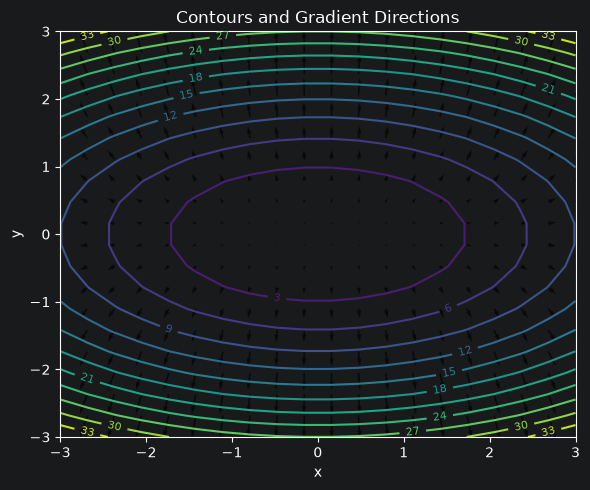

In [7]:
# Evaluate the function and its gradient at one point.
def f_xy(x, y):
    return x**2 + 3*y**2

def grad_f_xy(x, y):
    # The gradient is the vector of both partial derivatives.
    return np.array([2*x, 6*y])

print("f(2, -1):", f_xy(2, -1))
print("Gradient at (2, -1):", grad_f_xy(2, -1))

# Visualize function contours and gradient directions.
grid = np.linspace(-3, 3, 20)
Xg, Yg = np.meshgrid(grid, grid)
Zg = Xg**2 + 3*Yg**2
U, V = 2*Xg, 6*Yg

plt.figure(figsize=(6, 5))
contours = plt.contour(Xg, Yg, Zg, levels=12)
plt.clabel(contours, fontsize=8)
plt.quiver(Xg, Yg, U, V, alpha=0.65)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Contours and Gradient Directions")
plt.tight_layout()
plt.show()

## 9. The chain rule and backpropagation

If $y=f(u)$ and $u=g(x)$, then:

$$
\frac{dy}{dx}=\frac{dy}{du}\frac{du}{dx}
$$

Example:

$$
y=(3x+1)^2,\qquad
\frac{dy}{dx}=2(3x+1)\cdot3=6(3x+1)
$$

A neural network is a composition of functions. Backpropagation applies the chain rule repeatedly to determine how the loss changes with every parameter.

In [8]:
# Calculate the derivative of y = (3x + 1)^2 using the chain rule.
x0 = 2.0
u = 3*x0 + 1
dy_du = 2*u
du_dx = 3

chain_rule = dy_du * du_dx
direct = 6 * (3*x0 + 1)

print("Chain-rule derivative:", chain_rule)
print("Direct derivative:", direct)

Chain-rule derivative: 42.0
Direct derivative: 42.0


## 10. Loss functions

A loss function measures how far predictions are from their targets. For a single regression example, squared error is:

$$
L=(\\hat{y}-y)^2
$$

For $n$ examples, mean squared error (MSE) is:

$$
\\mathrm{MSE}=\\frac{1}{n}\\sum_{i=1}^{n}(\\hat{y}_i-y_i)^2
$$

Regression often uses MSE or mean absolute error. Classification commonly uses cross-entropy losses. The choice of loss depends on the task and model output.

In [9]:
# Calculate MSE for a small set of regression predictions.
y_true = np.array([2.0, 1.0, 4.0, 3.0])
y_pred = np.array([1.5, 1.2, 3.5, 2.0])
squared_errors = (y_pred - y_true)**2
mse = squared_errors.mean()

print("Squared errors:", squared_errors)
print("MSE:", mse)

Squared errors: [0.25 0.04 0.25 1.  ]
MSE: 0.385


## 11. Gradient Descent

Gradient descent updates parameters in the direction opposite to the gradient:

$$
\theta_{t+1} = \theta_t - \eta \nabla_\theta L(\theta_t)
$$

- $\theta$ represents the model parameters.
- $\eta$ is the learning rate.
- $\nabla_\theta L$ is the gradient of the loss.

A learning rate that is too small may make learning slow. One that is too large may overshoot the minimum or cause unstable optimization.

Final w: 2.993810299803573
Final loss: 3.83123885216492e-05


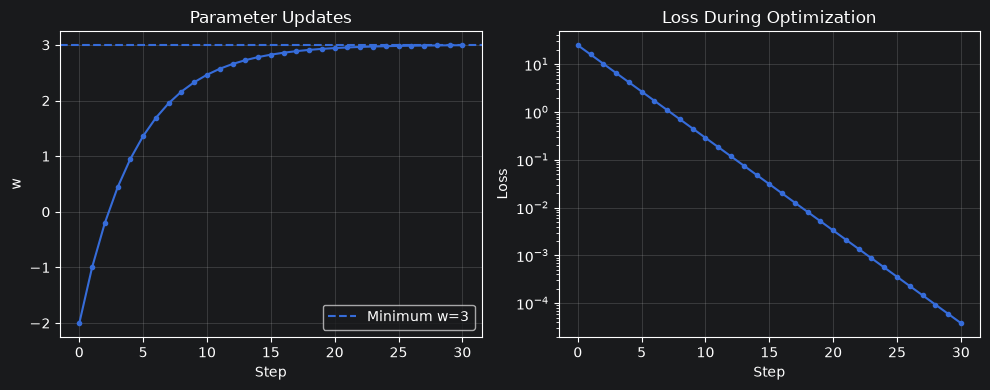

In [11]:
# Minimize f(w) = (w - 3)^2 with gradient descent.
def objective(w):
    return (w - 3)**2

def objective_gradient(w):
    return 2*(w - 3)

w = -2.0
learning_rate = 0.1
steps = 30
w_history = [w]
loss_history = [objective(w)]

for step in range(steps):
    # Compute the derivative at the current parameter.
    grad = objective_gradient(w)
    # Move against the gradient to reduce the objective.
    w = w - learning_rate * grad
    # Save values for inspection and plotting.
    w_history.append(w)
    loss_history.append(objective(w))

print("Final w:", w)
print("Final loss:", objective(w))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(w_history, marker="o", markersize=3)
axes[0].axhline(3, linestyle="--", label="Minimum w=3")
axes[0].set(title="Parameter Updates", xlabel="Step", ylabel="w")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(loss_history, marker="o", markersize=3)
axes[1].set(title="Loss During Optimization", xlabel="Step", ylabel="Loss")
axes[1].set_yscale("log")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Automatic differentiation with PyTorch

PyTorch can track tensor operations and calculate derivatives automatically. This is called **automatic differentiation**. For a scalar output, `.backward()` computes gradients for tracked tensors.

Gradients accumulate in `.grad` by default. In a training loop, clear them before each backward pass, commonly with `optimizer.zero_grad()`.

In [12]:
import torch

# Create a scalar tensor whose operations should be tracked.
x = torch.tensor(2.0, requires_grad=True)

# Define y = (3x + 1)^2.
y = (3*x + 1)**2

# Compute dy/dx.
y.backward()

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("x:", x.item())
print("y:", y.item())
print("Autograd derivative:", x.grad.item())
print("Analytical derivative:", 6*(3*x.item() + 1))

PyTorch version: 2.5.1+cu121
CUDA available: True
x: 2.0
y: 49.0
Autograd derivative: 42.0
Analytical derivative: 42.0


In [13]:
# Demonstrate gradient accumulation.
x = torch.tensor(2.0, requires_grad=True)

(x**2).backward()
print("After first backward (2x):", x.grad.item())  # 4

(3*x).backward()
print("After second backward (accumulated):", x.grad.item())  # 4 + 3 = 7

# Clear the gradient before computing another one.
x.grad.zero_()
(x**2).backward()
print("After clearing gradients:", x.grad.item())  # 4

After first backward (2x): 4.0
After second backward (accumulated): 7.0
After clearing gradients: 4.0


## 13. End-to-end example: fit a line in PyTorch

We will learn parameters for:

$$
\\hat{y}=wx+b
$$

The synthetic targets are generated approximately from $y=2x+1$. This small model demonstrates the full learning loop: predictions, loss, gradients, and parameter updates.

In [14]:
# Create reproducible synthetic regression data.
torch.manual_seed(42)
x_train = torch.linspace(-2, 2, 100).reshape(-1, 1)
noise = 0.2 * torch.randn_like(x_train)
y_train = 2*x_train + 1 + noise

# Initialize learnable parameters.
w = torch.nn.Parameter(torch.randn(1, 1))
b = torch.nn.Parameter(torch.zeros(1))

# Configure the optimizer and loss function.
optimizer = torch.optim.SGD([w, b], lr=0.05)
loss_fn = torch.nn.MSELoss()
loss_history = []

for epoch in range(200):
    optimizer.zero_grad()              # Clear old gradients.
    y_pred = x_train @ w + b           # Forward pass.
    loss = loss_fn(y_pred, y_train)    # Measure prediction error.
    loss.backward()                    # Calculate gradients.
    optimizer.step()                   # Update w and b.
    loss_history.append(loss.item())   # Store loss for plotting.

print("Learned w:", w.item())
print("Learned b:", b.item())
print("Final MSE:", loss_history[-1])

Learned w: 1.9970520734786987
Learned b: 1.011952519416809
Final MSE: 0.03851611167192459


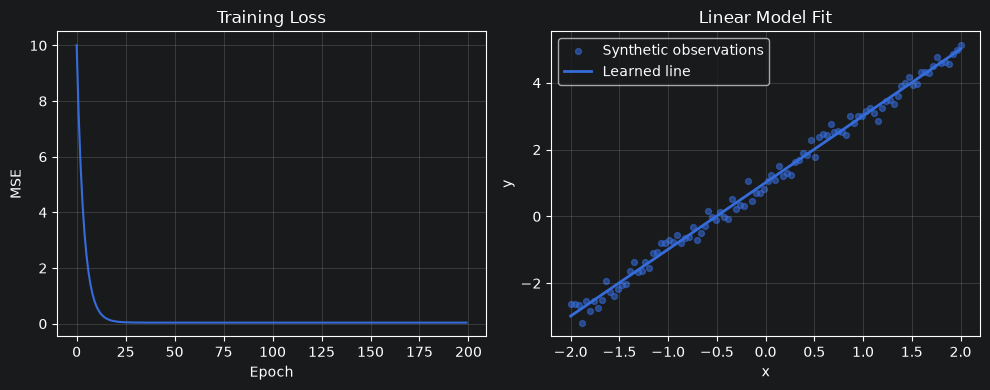

In [15]:
# Plot training loss and the fitted line.
with torch.no_grad():
    y_fitted = x_train @ w + b

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(loss_history)
axes[0].set(title="Training Loss", xlabel="Epoch", ylabel="MSE")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(x_train.numpy(), y_train.numpy(), s=18, alpha=0.55,
                label="Synthetic observations")
axes[1].plot(x_train.numpy(), y_fitted.numpy(), linewidth=2,
             label="Learned line")
axes[1].set(title="Linear Model Fit", xlabel="x", ylabel="y")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 14. From mathematics to a neural-network training loop

A typical training step follows this sequence:

1. **Input:** provide a batch of examples.
2. **Forward pass:** calculate predictions using weights, biases, and activations.
3. **Loss:** compare predictions with targets.
4. **Backward pass:** apply the chain rule to calculate parameter gradients.
5. **Optimization:** update parameters using an optimizer.
6. **Repeat:** process more batches over multiple epochs.

This is the conceptual bridge between the mathematics in this notebook and the neural-network implementations in later notebooks.

## 15. Common mistakes

- `A * B` and `A @ B` are different operations.
- Matrix multiplication requires matching inner dimensions.
- The function value $f(x)$ is not the derivative $f'(x)$.
- Gradient descent subtracts the gradient.
- A learning rate that is too large can destabilize optimization.
- PyTorch gradients accumulate unless they are cleared.
- Low training loss does not guarantee generalization; validation and test data are still necessary.

## 16. Exercises

1. **Vector operations:** Create two length-five vectors. Compute their sum, element-wise product, and dot product. Explain the difference.
2. **Shapes:** Multiply a `(8, 4)` matrix by a `(4, 3)` matrix. What is the output shape? Why is `(8, 4) @ (5, 3)` invalid?
3. **Derivative:** For $f(x)=3x^2-4x+2$, derive the derivative and verify it numerically at $x=2$.
4. **Gradient descent:** Minimize $g(w)=(w+4)^2$ starting from `w=5`. Compare learning rates `0.01`, `0.1`, and `0.8`.
5. **Autograd:** Use PyTorch to differentiate $y=x^3-2x^2+5x$ at `x=3`. Compare against the analytical derivative.
6. **Linear regression:** Modify the synthetic data to approximate $y=-1.5x+0.7$. Train the model and compare learned parameters with the generating values.
7. **Conceptual:** Explain why the chain rule is necessary for a network with multiple layers.

## 17. Quick reference

| Concept | Formula / API |
|---|---|
| Dot product | $\\mathbf{w}\\cdot\\mathbf{x}=\\sum_i w_i x_i$ |
| Dense layer | $Z=XW+b$ |
| Derivative | Instantaneous rate of change |
| Gradient | Vector of partial derivatives |
| Chain rule | $\\frac{dy}{dx}=\\frac{dy}{du}\\frac{du}{dx}$ |
| Mean squared error | $\\frac{1}{n}\\sum_i(\\hat{y}_i-y_i)^2$ |
| Gradient descent | $\theta\\leftarrow\theta-\eta\nabla_\theta L$ |
| PyTorch backward pass | `loss.backward()` |
| Clear gradients | `optimizer.zero_grad()` |
| Update parameters | `optimizer.step()` |

### Key takeaway

Neural networks are built from numerical representations, linear algebra, nonlinear functions, derivatives, the chain rule, loss functions, and optimization. These foundations will support later topics such as backpropagation, CNNs, Transformers, medical imaging, and bioinformatics.